In [1]:
import NNMFit
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
import os
plotting_path = "/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks/unblind/step1_hese_flux_reunblind/plots_fit_result"
os.makedirs(plotting_path, exist_ok=True)

In [3]:
import matplotlib.font_manager as font_manager
font_axis_label = {'family': 'serif',
        'color':  'black',
        'weight': 'normal',
        'size': 22,
        }
font_title = {'family': 'serif',
        'color':  'black',
        'weight': 'bold',
        'size': 20,
        }
font_legend = font_manager.FontProperties(family='serif',
                                   weight='normal',
                                   style='normal', size=13)

plt.rcParams["figure.figsize"] = (6,6)
plt.rcParams.update({'font.family':'serif'})

In [4]:
def get_1sigma(scan, parameter, bestfit_val, threshold=1.0):
    """Find where dllh crosses threshold via sign-change detection + linear interpolation."""
    scan_sorted = scan.sort_values(parameter).reset_index(drop=True)
    x = scan_sorted[parameter].values
    delta = scan_sorted["dllh"].values - threshold

    sign_changes = np.where(np.diff(np.sign(delta)))[0]
    roots = []
    for idx in sign_changes:
        x0, x1 = x[idx], x[idx + 1]
        y0, y1 = delta[idx], delta[idx + 1]
        roots.append(x0 - y0 * (x1 - x0) / (y1 - y0))

    roots = np.array(roots)
    lower = roots[roots < bestfit_val]
    upper = roots[roots > bestfit_val]

    err_lo = bestfit_val - lower[-1] if len(lower) else np.nan
    err_hi = upper[0] - bestfit_val if len(upper) else np.nan
    return err_lo, err_hi

In [5]:
scan_dir_dict = {
    # previous fit without detector priors (`priors` key was not read by NNMFit), plus its finer scan:
    # "nbestfit50_all_param_2sigma_1D_10steps_PassingHESE" : "/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/dag_scans/flavor_globalfit/hese/unblind/step1_hese_flux_try2/data_fits/nbestfit50_all_param_2sigma_1D_10steps_PassingHESE",
    # "nbestfit50_all_param_2sigma_1D_10steps_PassingHESE_fine" : "/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/dag_scans/flavor_globalfit/hese/unblind/step1_hese_flux_try2/data_fits/nbestfit50_all_param_2sigma_1D_10steps_PassingHESE_fine",

    # fit with the detector priors applied (fixed `prior` key)
    "nbestfit50_all_param_2sigma_1D_10steps_PassingHESE_fixedprior" :
        "/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/dag_scans/flavor_globalfit/hese/unblind/step1_hese_flux_try2/data_fits/nbestfit50_all_param_2sigma_1D_10steps_PassingHESE_fixedprior",
}

In [6]:
drop_unsuccessful = False
scan_dict = {}
bestfits = {}

for name, scan_dir in scan_dir_dict.items():
    print(name)
    # use force_read if new scan points are produced
    scan_dict[name] = NNMFit.utilities.ScanHandler(scan_dir,dump=False,drop_unsuccessful=drop_unsuccessful)
    bestfits[name] = scan_dict[name].get_freefit(drop_unsuccessful="True")

nbestfit50_all_param_2sigma_1D_10steps_PassingHESE_fixedprior


## Best fit comparison

Compare best fit parameter values across all scans and identify which optimizer found the lowest likelihood.

In [7]:
# Compare best fit values across all scans
df_compare = pd.DataFrame({name: bestfits[name] for name in scan_dir_dict}).T
display(df_compare)

best_name = df_compare["llh"].idxmin()
print(f"\nBest likelihood: '{best_name}'  (llh = {df_compare.loc[best_name, 'llh']:.6f})")
for name in scan_dir_dict:
    if name != best_name:
        delta = df_compare.loc[name, "llh"] - df_compare.loc[best_name, "llh"]
        print(f"  {name} is worse by dllh = {delta:.4f}")

,CR_grad,astro_norm,barr_h,barr_w,barr_y,barr_z,combined_muongun_norm,conv_norm,delta_gamma,dom_eff,fit_success,gamma_astro,ice_abs,ice_crystal,ice_holep0,ice_holep1,ice_scat,llh,muongun_asymmetry,prompt_norm
nbestfit50_all_param_2sigma_1D_10steps_PassingHESE_fixedprior,-0.0929,1.682573,0.001678,0.011094,0.051466,0.029602,0.577458,1.025779,-0.002971,0.986431,True,2.816197,1.003278,0.925485,0.101934,-0.065337,0.985913,182.959306,-0.005583,0.994266



Best likelihood: 'nbestfit50_all_param_2sigma_1D_10steps_PassingHESE_fixedprior'  (llh = 182.959306)


## Combined scan

The scans above use the same likelihood (same configs, freefit minima agree), only the scanned
parameters and step sizes differ. Their 1D scan points are merged per parameter:
$-2\Delta\log\mathcal{L}$ is computed relative to the lowest freefit llh of all scans, and for scan
points at the same parameter value the lowest llh is kept. Parameters only scanned in one scan keep
that profile. All cells below use this combined scan (`best_name = "combined"`).


In [8]:
class CombinedScan:
    """1D scans of several scan directories with the same likelihood, merged per parameter.
    dllh is computed relative to the lowest freefit llh of all scans; for scan points at the
    same parameter value the lowest llh is kept."""

    def __init__(self, scans, bestfits):
        self.scans = scans
        self.bestfit = min(bestfits.values(), key=lambda bf: bf["llh"])
        self.llh_min = self.bestfit["llh"]

    def get_scan_df(self, param_name, drop_unsuccessful=None):
        dfs = []
        for name, scan in self.scans.items():
            try:
                df = scan.get_scan_df(param_name=param_name, dllh_ref=self.llh_min, drop_unsuccessful=drop_unsuccessful)
            except Exception:
                continue
            if len(df):
                dfs.append(df.assign(scan=name))
        if not dfs:
            raise KeyError(f"{param_name} is not scanned in any of {list(self.scans)}")
        df = pd.concat(dfs, ignore_index=True)
        df["_x"] = df[param_name].astype(float).round(10)
        df = df.sort_values("llh").drop_duplicates("_x").drop(columns="_x")
        return df.sort_values(param_name).reset_index(drop=True)


scan_dict["combined"] = CombinedScan({name: scan_dict[name] for name in scan_dir_dict},
                                     {name: bestfits[name] for name in scan_dir_dict})
bestfits["combined"] = scan_dict["combined"].bestfit
best_name = "combined"

print(f"combined best fit llh = {bestfits[best_name]['llh']:.6f}")
for parameter in ["astro_norm", "gamma_astro", "conv_norm", "prompt_norm", "combined_muongun_norm", "muongun_asymmetry"]:
    df = scan_dict[best_name].get_scan_df(param_name=parameter, drop_unsuccessful=drop_unsuccessful)
    print(f"{parameter}: {len(df)} points, {df['scan'].value_counts().to_dict()}, min dllh = {df['dllh'].min():.3g}")


combined best fit llh = 182.959306
astro_norm: 10 points, {'nbestfit50_all_param_2sigma_1D_10steps_PassingHESE_fixedprior': 10}, min dllh = 0.06
gamma_astro: 10 points, {'nbestfit50_all_param_2sigma_1D_10steps_PassingHESE_fixedprior': 10}, min dllh = 0.000943
conv_norm: 10 points, {'nbestfit50_all_param_2sigma_1D_10steps_PassingHESE_fixedprior': 10}, min dllh = 0.00157
prompt_norm: 10 points, {'nbestfit50_all_param_2sigma_1D_10steps_PassingHESE_fixedprior': 10}, min dllh = 0.00188
combined_muongun_norm: 10 points, {'nbestfit50_all_param_2sigma_1D_10steps_PassingHESE_fixedprior': 10}, min dllh = 0.00886
muongun_asymmetry: 10 points, {'nbestfit50_all_param_2sigma_1D_10steps_PassingHESE_fixedprior': 10}, min dllh = 0.0205


## Free fit parameter distributions

Histograms of all free parameters across the best-fit ensemble. The red line marks the best fit value for each parameter.

0 CR_grad
1 astro_norm
2 barr_h
3 barr_w
4 barr_y
5 barr_z
6 combined_muongun_norm
7 conv_norm
8 delta_gamma
9 dom_eff
10 fit_success
11 gamma_astro
12 ice_abs
13 ice_crystal
14 ice_holep0
15 ice_holep1
16 ice_scat
17 llh
18 muongun_asymmetry
19 prompt_norm


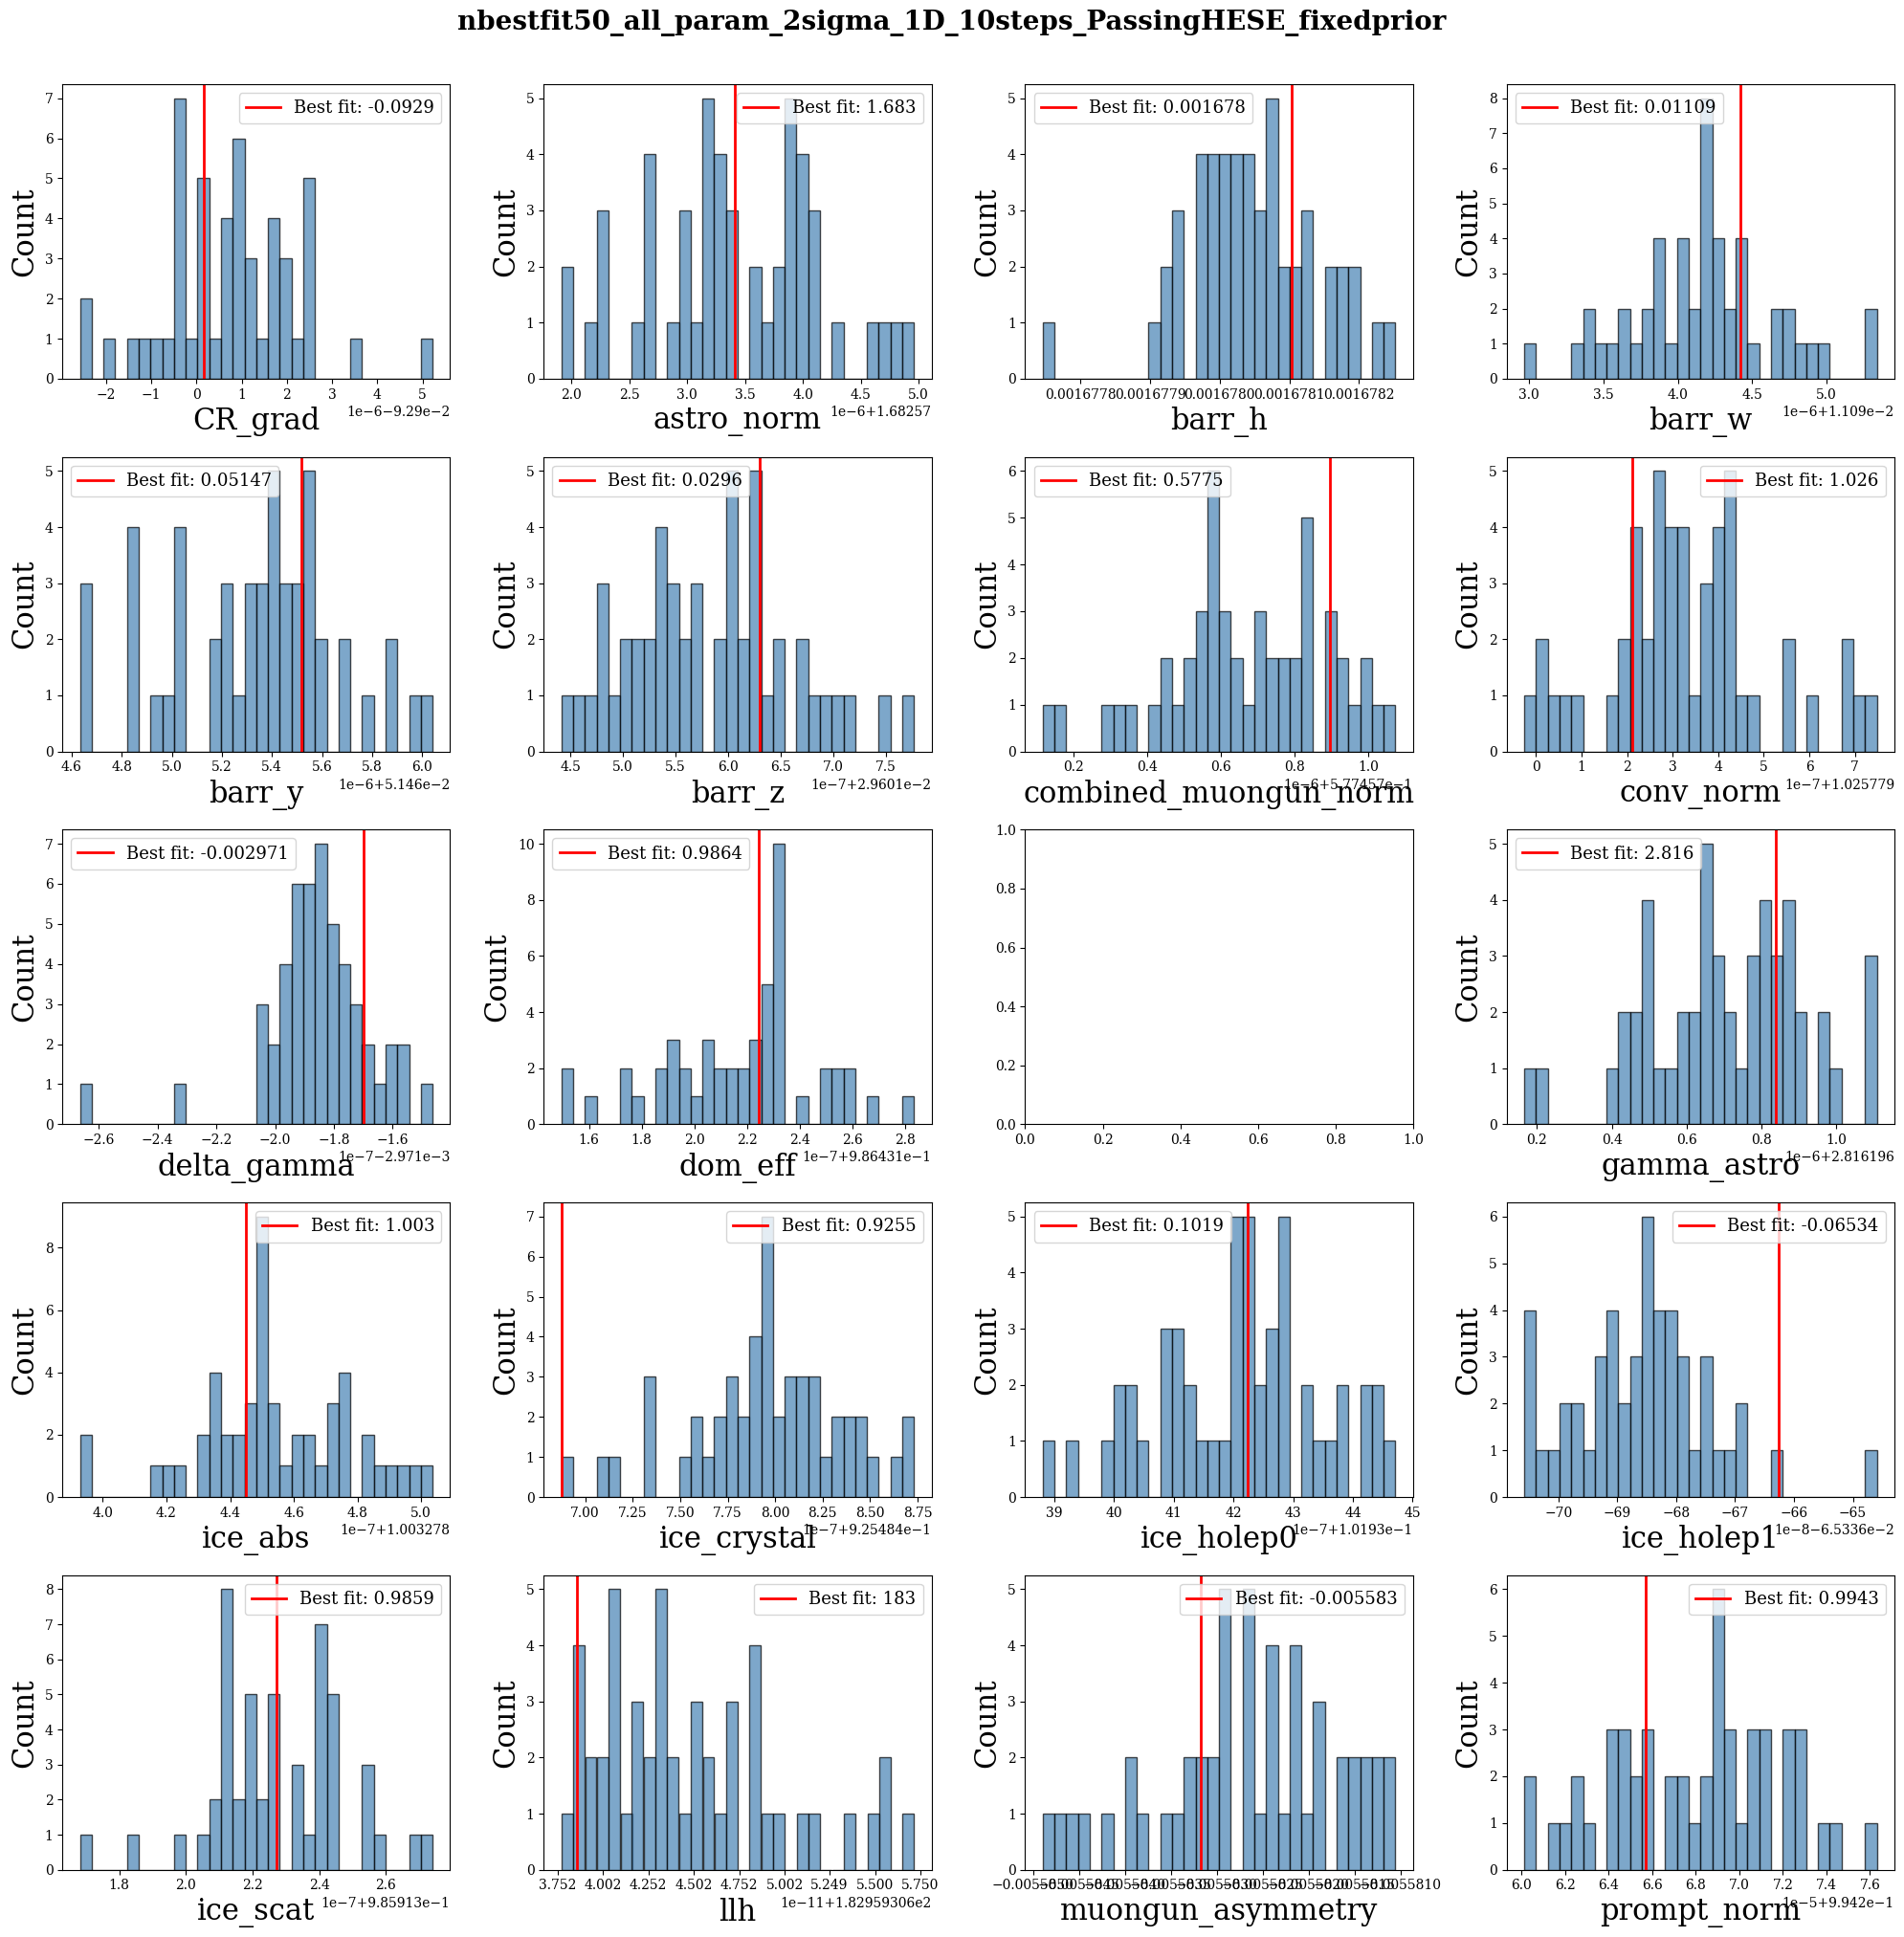

In [9]:
for name in scan_dir_dict:
    freefit_df = scan_dict[name].get_raw_df().loc["freefit"]
    variables = freefit_df.keys()
    bestfit = bestfits[name]

    ncols = 4
    nrows = int(np.ceil(len(variables) / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
    fig.suptitle(name, **font_title, y=1.01)
    axes = axes.flatten()

    for i, var in enumerate(variables):
        print(i,var)
        if var == "fit_success":continue
        ax = axes[i]
        values = freefit_df[var].dropna()
        ax.hist(values, bins=30, color="steelblue", alpha=0.7, edgecolor="black")
        if var in bestfit:
            bf_val = bestfit[var]
            ax.axvline(x=bf_val, color="red", linewidth=2, label=f"Best fit: {bf_val:.4g}")
            ax.legend(prop=font_legend)
        ax.set_xlabel(var, fontdict=font_axis_label)
        ax.set_ylabel("Count", fontdict=font_axis_label)

    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)

    plt.tight_layout()
    plt.savefig(f"{plotting_path}/freefit_param_hist_{name}.png", bbox_inches="tight")
    plt.show()


## Likelihood scan comparison

Overlay of the $-2\Delta\log\mathcal{L}$ profiles for `astro_norm` and `gamma_astro` across all scans. Dashed verticals mark each best fit; dotted verticals mark the 1σ boundaries.

nbestfit50_all_param_2sigma_1D_10steps_PassingHESE_fixedprior | astro_norm: 1.683 +0.4974 / -0.473
nbestfit50_all_param_2sigma_1D_10steps_PassingHESE_fixedprior | gamma_astro: 2.816 +0.168 / -0.1702


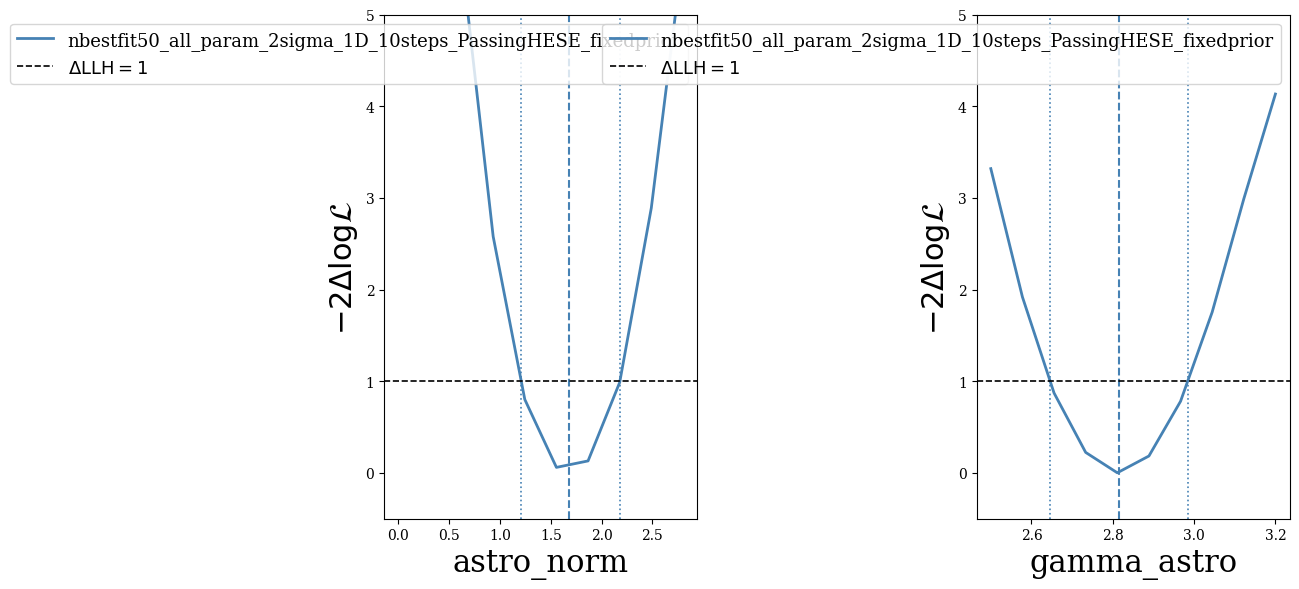

In [10]:
parameters = ["astro_norm", "gamma_astro"]
colors = ["steelblue", "darkorange", "green"]

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

for ax, parameter in zip(axes, parameters):
    for color, name in zip(colors, scan_dir_dict):
        scan = scan_dict[name].get_scan_df(param_name=parameter, drop_unsuccessful=drop_unsuccessful)
        bestfit_val = bestfits[name][parameter]
        err_lo, err_hi = get_1sigma(scan, parameter, bestfit_val)

        print(f"{name} | {parameter}: {bestfit_val:.4g} +{err_hi:.4g} / -{err_lo:.4g}")

        scan_sorted = scan.sort_values(parameter)
        ax.plot(scan_sorted[parameter], scan_sorted["dllh"], color=color, linewidth=2, label=name)
        ax.axvline(bestfit_val, color=color, linewidth=1.5, linestyle="--")
        ax.axvline(bestfit_val - err_lo, color=color, linestyle=":", linewidth=1.2)
        ax.axvline(bestfit_val + err_hi, color=color, linestyle=":", linewidth=1.2)

    ax.axhline(1.0, color="black", linestyle="--", linewidth=1.2, label=r"$\Delta\mathrm{LLH} = 1$")
    ax.set_xlabel(parameter, fontdict=font_axis_label)
    ax.set_ylabel(r"$-2\Delta\mathrm{log}\mathcal{L}$", fontdict=font_axis_label)
    ax.set_ylim(-0.5, 5)
    ax.legend(prop=font_legend)

plt.tight_layout()
plt.savefig(f"{plotting_path}/compare_signal_scan.png", bbox_inches="tight")
plt.show()


## Best fit scan — 1σ errors

Likelihood profile for `astro_norm` and `gamma_astro` from the best scan. The red shaded band marks the 1σ interval where $-2\Delta\log\mathcal{L} < 1$.

<>:20: DeprecationWarning: invalid escape sequence '\s'
<>:20: DeprecationWarning: invalid escape sequence '\s'
/tmp/ipykernel_2056180/2334333109.py:20: DeprecationWarning: invalid escape sequence '\s'
  label=f"$1\sigma$: $+{err_hi:.4g}$ / $-{err_lo:.4g}$")


astro_norm: 1.683 +0.4974 / -0.473
gamma_astro: 2.816 +0.168 / -0.1702


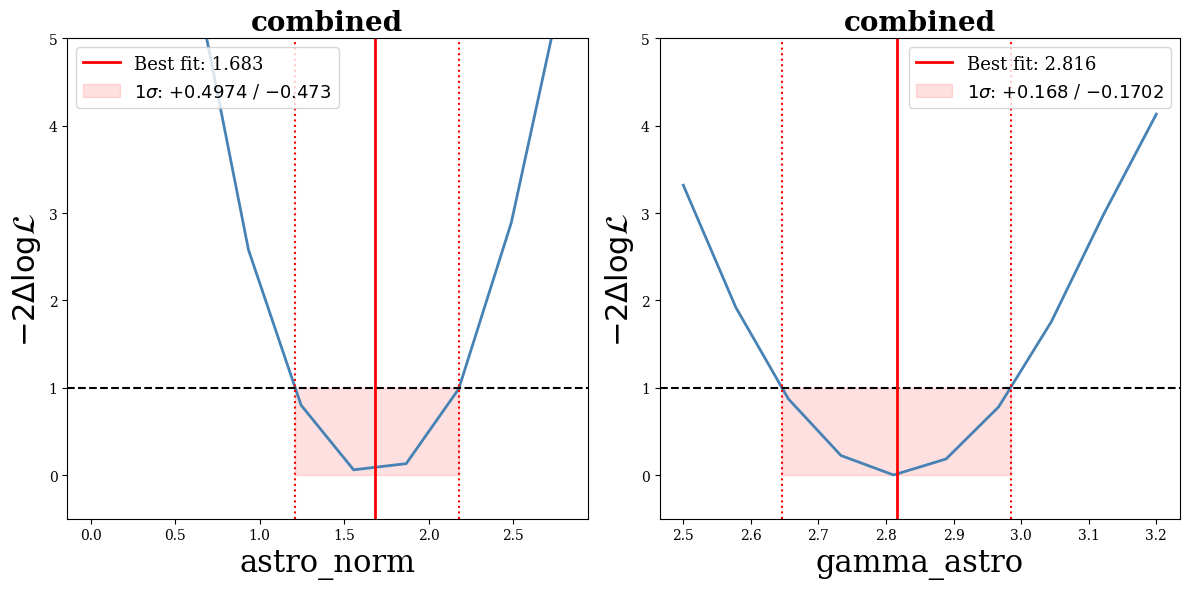

In [11]:
parameters = ["astro_norm", "gamma_astro"]

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

for ax, parameter in zip(axes, parameters):
    scan = scan_dict[best_name].get_scan_df(param_name=parameter, drop_unsuccessful=drop_unsuccessful)
    bestfit_val = bestfits[best_name][parameter]
    err_lo, err_hi = get_1sigma(scan, parameter, bestfit_val)

    print(f"{parameter}: {bestfit_val:.4g} +{err_hi:.4g} / -{err_lo:.4g}")

    scan_sorted = scan.sort_values(parameter)
    ax.plot(scan_sorted[parameter], scan_sorted["dllh"], color="steelblue", linewidth=2)
    ax.axhline(1.0, color="black", linestyle="--", linewidth=1.5)
    ax.axvline(bestfit_val, color="red", linewidth=2, label=f"Best fit: {bestfit_val:.4g}")
    ax.axvline(bestfit_val - err_lo, color="red", linestyle=":", linewidth=1.5)
    ax.axvline(bestfit_val + err_hi, color="red", linestyle=":", linewidth=1.5)
    ax.fill_betweenx([0, 1], bestfit_val - err_lo, bestfit_val + err_hi,
                     color="red", alpha=0.12,
                     label=f"$1\sigma$: $+{err_hi:.4g}$ / $-{err_lo:.4g}$")

    ax.set_xlabel(parameter, fontdict=font_axis_label)
    ax.set_ylabel(r"$-2\Delta\mathrm{log}\mathcal{L}$", fontdict=font_axis_label)
    ax.set_title(best_name, **font_title)
    ax.set_ylim(-0.5, 5)
    ax.legend(prop=font_legend)

plt.tight_layout()
plt.savefig(f"{plotting_path}/best_signal_scan_{best_name}.png", bbox_inches="tight")
plt.show()


## All fit parameters — 1σ errors

Same likelihood profiles as above, but for every parameter included in the 1D scan.
Each panel shows $-2\Delta\log\mathcal{L}$ versus the scanned parameter, with the best
fit (solid red), the 1σ boundaries (dotted red) and the 1σ band where
$-2\Delta\log\mathcal{L} < 1$ (red shading). Parameters whose profile does not cross
the threshold inside the scanned range have an open (`nan`) error on that side —
the scan window is then too narrow to contain the 1σ bound.


<>:48: DeprecationWarning: invalid escape sequence '\s'
<>:48: DeprecationWarning: invalid escape sequence '\s'
/tmp/ipykernel_2056180/1278081557.py:48: DeprecationWarning: invalid escape sequence '\s'
  label=f"$1\sigma$: $+{err_hi:.4g}$ / $-{err_lo:.4g}$")


astro_norm: 1.683 +0.4974 / -0.473
gamma_astro: 2.816 +0.168 / -0.1702
conv_norm: 1.026 +0.1886 / -0.1891
prompt_norm: 0.9943 +2.534 / -nan
combined_muongun_norm: 0.5775 +0.2503 / -0.2127
muongun_asymmetry: -0.005583 +0.9513 / -0.7101
delta_gamma: -0.002971 +0.04868 / -0.04929
CR_grad: -0.0929 +0.9158 / -nan
barr_h: 0.001678 +0.147 / -0.1467
barr_w: 0.01109 +0.3959 / -0.3976
barr_y: 0.05147 +0.2756 / -0.2723
barr_z: 0.0296 +0.1075 / -0.1056
dom_eff: 0.9864 +0.04584 / -0.04682
ice_scat: 0.9859 +0.03505 / -0.03573
ice_abs: 1.003 +0.03452 / -0.03647
ice_crystal: 0.9255 +0.07004 / -0.07577
ice_holep0: 0.1019 +0.1675 / -0.1947
ice_holep1: -0.06534 +0.02557 / -0.02695


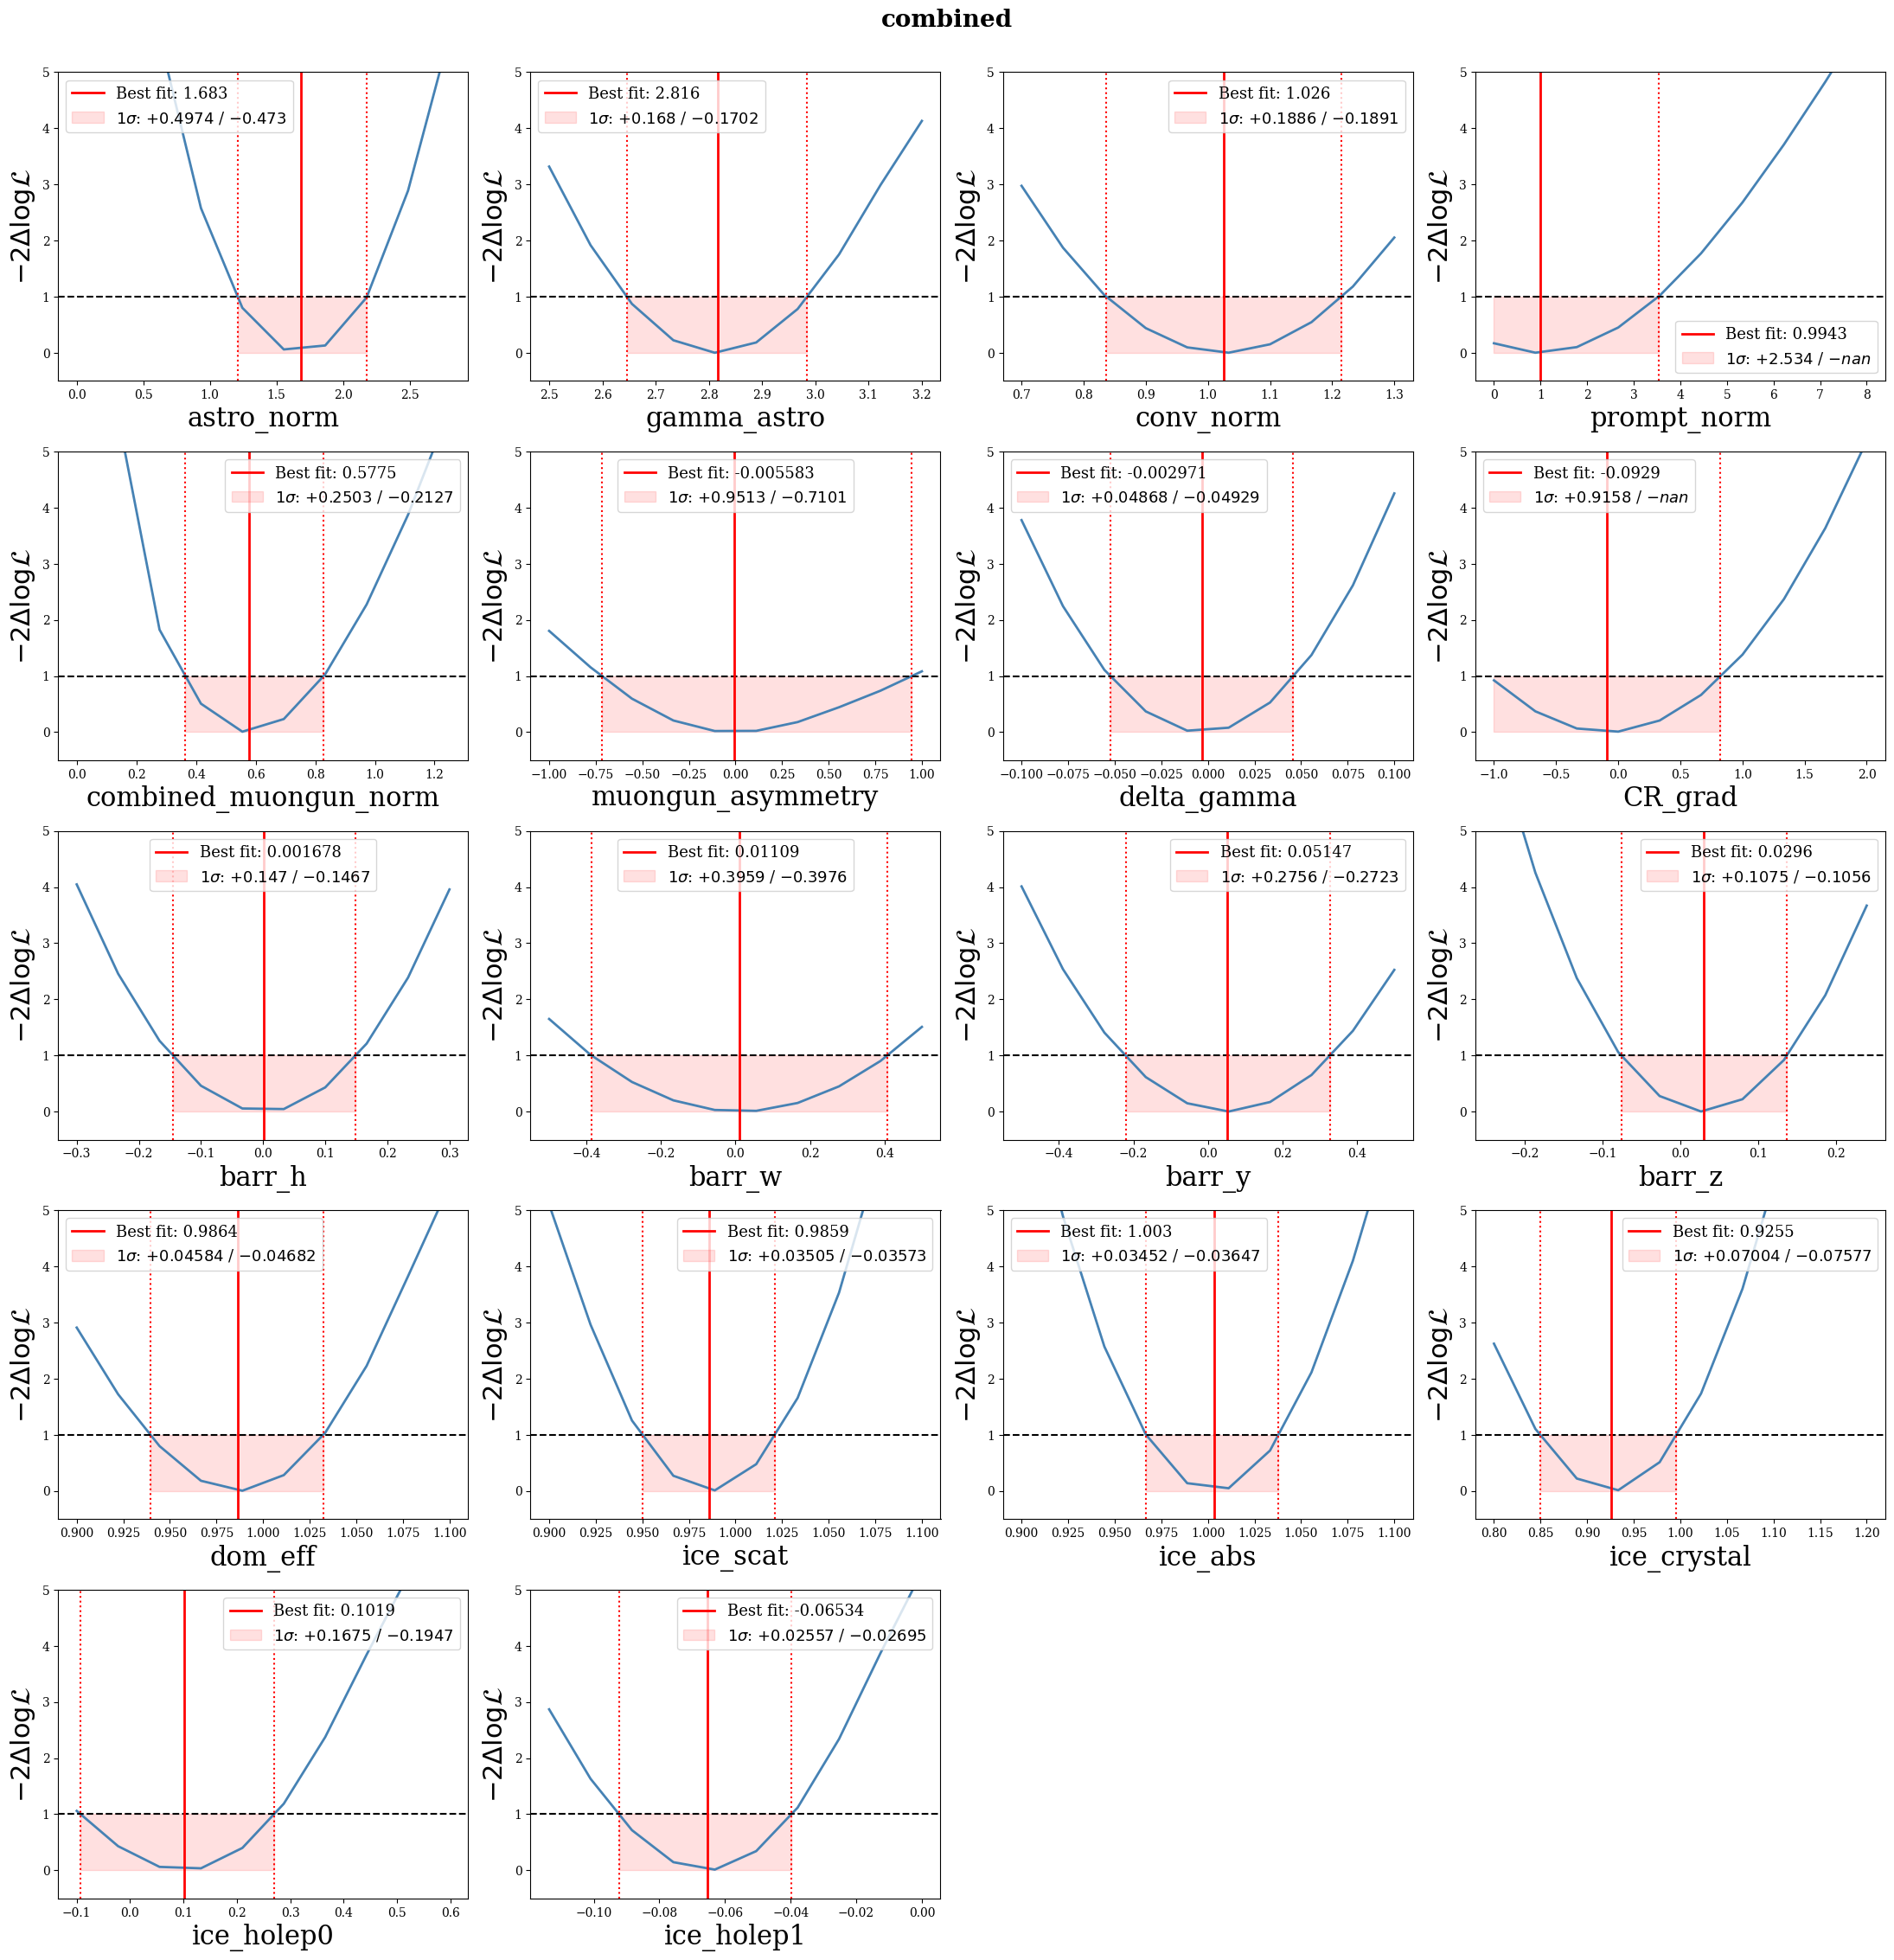

In [12]:
# all parameters covered by the 1D scan, in scan-config order
scan_parameters = [
    "astro_norm", "gamma_astro",
    "conv_norm", "prompt_norm", "combined_muongun_norm", "muongun_asymmetry",
    "delta_gamma", "CR_grad", "barr_h", "barr_w", "barr_y", "barr_z",
    "dom_eff", "ice_scat", "ice_abs", "ice_crystal", "ice_holep0", "ice_holep1",
]

# keep only the parameters that are actually present in the best scan
available = []
for parameter in scan_parameters:
    try:
        scan_dict[best_name].get_scan_df(param_name=parameter, drop_unsuccessful=drop_unsuccessful)
        available.append(parameter)
    except Exception as e:
        print(f"skipping {parameter}: {e}")

ncols = 4
nrows = int(np.ceil(len(available) / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 4.5 * nrows))
fig.suptitle(best_name, **font_title, y=1.005)
axes = axes.flatten()

errors = {}

for ax, parameter in zip(axes, available):
    scan = scan_dict[best_name].get_scan_df(param_name=parameter, drop_unsuccessful=drop_unsuccessful)
    bestfit_val = bestfits[best_name][parameter]
    err_lo, err_hi = get_1sigma(scan, parameter, bestfit_val)
    errors[parameter] = {"bestfit": bestfit_val, "err_lo": err_lo, "err_hi": err_hi}

    print(f"{parameter}: {bestfit_val:.4g} +{err_hi:.4g} / -{err_lo:.4g}")

    scan_sorted = scan.sort_values(parameter)
    ax.plot(scan_sorted[parameter], scan_sorted["dllh"], color="steelblue", linewidth=2)
    ax.axhline(1.0, color="black", linestyle="--", linewidth=1.5)
    ax.axvline(bestfit_val, color="red", linewidth=2, label=f"Best fit: {bestfit_val:.4g}")

    if np.isfinite(err_lo):
        ax.axvline(bestfit_val - err_lo, color="red", linestyle=":", linewidth=1.5)
    if np.isfinite(err_hi):
        ax.axvline(bestfit_val + err_hi, color="red", linestyle=":", linewidth=1.5)

    lo_edge = bestfit_val - err_lo if np.isfinite(err_lo) else scan_sorted[parameter].min()
    hi_edge = bestfit_val + err_hi if np.isfinite(err_hi) else scan_sorted[parameter].max()
    ax.fill_betweenx([0, 1], lo_edge, hi_edge, color="red", alpha=0.12,
                     label=f"$1\sigma$: $+{err_hi:.4g}$ / $-{err_lo:.4g}$")

    ax.set_xlabel(parameter, fontdict=font_axis_label)
    ax.set_ylabel(r"$-2\Delta\mathrm{log}\mathcal{L}$", fontdict=font_axis_label)
    ax.set_ylim(-0.5, 5)
    ax.legend(prop=font_legend)

for ax in axes[len(available):]:
    ax.set_visible(False)

plt.tight_layout()
plt.savefig(f"{plotting_path}/all_param_scan_{best_name}.png", bbox_inches="tight")
plt.show()


### Summary of the 1σ intervals

All best fit values with their asymmetric 1σ errors collected in one table, followed by
a pull-style overview where every parameter is shown relative to its own best fit so the
intervals can be compared on a single axis.


,bestfit,err_lo,err_hi,1sigma_lo,1sigma_hi
astro_norm,1.682573,0.472965,0.497436,1.209609,2.180010
gamma_astro,2.816197,0.170205,0.168005,2.645992,2.984202
conv_norm,1.025779,0.189118,0.188573,0.836661,1.214352
prompt_norm,0.994266,NaN,2.533791,NaN,3.528057
combined_muongun_norm,0.577458,0.212653,0.250281,0.364805,0.827739
muongun_asymmetry,-0.005583,0.710116,0.951287,-0.715699,0.945704
delta_gamma,-0.002971,0.049286,0.048683,-0.052257,0.045712
CR_grad,-0.092900,NaN,0.915814,NaN,0.822914
barr_h,0.001678,0.146658,0.146999,-0.144979,0.148677
barr_w,0.011094,0.397588,0.395923,-0.386494,0.407018


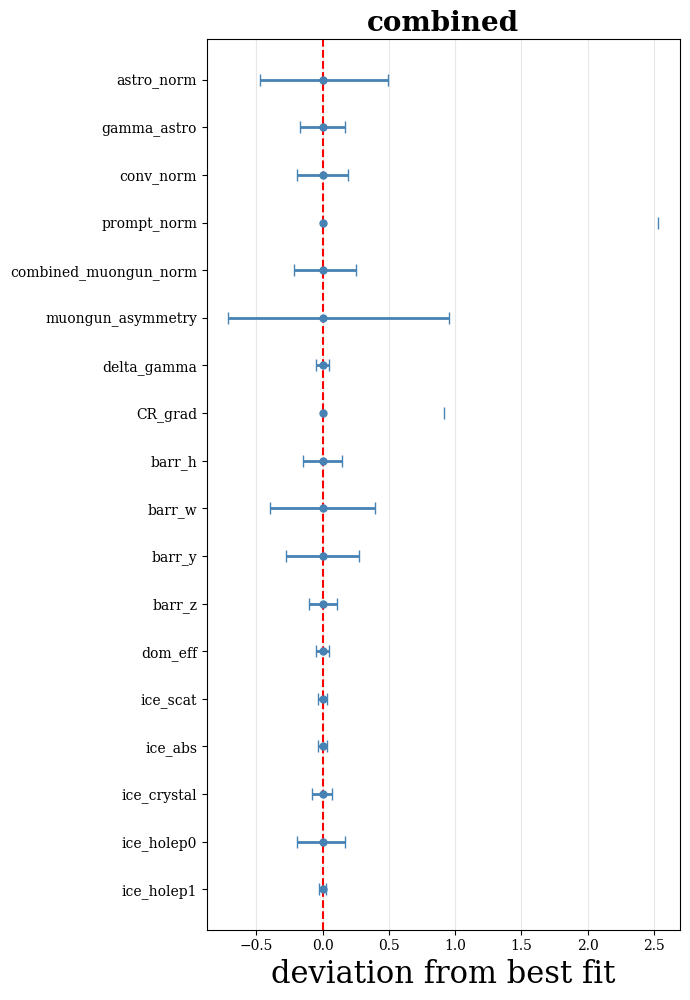

In [13]:
df_errors = pd.DataFrame(errors).T[["bestfit", "err_lo", "err_hi"]]
df_errors["1sigma_lo"] = df_errors["bestfit"] - df_errors["err_lo"]
df_errors["1sigma_hi"] = df_errors["bestfit"] + df_errors["err_hi"]
display(df_errors)

# overview: every parameter relative to its own best fit value
fig, ax = plt.subplots(figsize=(7, 0.45 * len(df_errors) + 2))
ypos = np.arange(len(df_errors))[::-1]

ax.errorbar(np.zeros(len(df_errors)), ypos,
            xerr=[df_errors["err_lo"].values, df_errors["err_hi"].values],
            fmt="o", color="steelblue", ecolor="steelblue",
            elinewidth=2, capsize=4, markersize=5)
ax.axvline(0, color="red", linewidth=1.5, linestyle="--")

ax.set_yticks(ypos)
ax.set_yticklabels(df_errors.index)
ax.set_xlabel("deviation from best fit", fontdict=font_axis_label)
ax.set_title(best_name, **font_title)
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig(f"{plotting_path}/errors_overview_{best_name}.png", bbox_inches="tight")
plt.show()


## Best fit parameters

Parameters from the best scan printed in `input_params` YAML format, ready to paste into the analysis config.

In [14]:
bf = bestfits[best_name]

signal      = ["astro_norm", "gamma_astro"]
flux_nuis   = ["conv_norm", "prompt_norm", "combined_muongun_norm", "muongun_asymmetry",
               "CR_grad", "barr_h", "barr_w", "barr_y", "barr_z", "delta_gamma"]
det_nuis    = ["dom_eff", "ice_abs", "ice_crystal", "ice_holep0", "ice_holep1", "ice_scat"]

lines = [f"# best fit from scan: {best_name}", "input_params:"]
for label, group in [("signal", signal), ("flux nuisance", flux_nuis), ("detector nuisance", det_nuis)]:
    lines.append(f"  ### {label}")
    for p in group:
        lines.append(f"  {p}: {bf[p]}")
    lines.append("")

print("\n".join(lines))

# best fit from scan: combined
input_params:
  ### signal
  astro_norm: 1.6825734159118497
  gamma_astro: 2.816196838766814

  ### flux nuisance
  conv_norm: 1.0257792114595201
  prompt_norm: 0.9942656966380423
  combined_muongun_norm: 0.5774578958732324
  muongun_asymmetry: -0.005583175514875674
  CR_grad: -0.092899832450107
  barr_h: 0.0016781034115442464
  barr_w: 0.011094423314870525
  barr_y: 0.05146551815499453
  barr_z: 0.02960162990504217
  delta_gamma: -0.002971169778702553

  ### detector nuisance
  dom_eff: 0.9864312246703404
  ice_abs: 1.0032784449819572
  ice_crystal: 0.9254846874724542
  ice_holep0: 0.10193422363790372
  ice_holep1: -0.06533666265595511
  ice_scat: 0.9859132272002629



In [15]:
bestfits[best_name]
idx = bestfits[best_name].name
idx

41

## Best fit results — LaTeX table

Best fit values with 1σ asymmetric errors for all parameters, formatted as a LaTeX table.

In [16]:
n_decimals = 3

# best fit and 1σ errors from the all-parameter scan above
all_parameters = scan_parameters
scan_results = {p: (e["bestfit"], e["err_lo"], e["err_hi"]) for p, e in errors.items()}

# prompt_norm: the profile stays below 1 down to the physical bound prompt_norm = 0,
# so the lower error is set by hand to the distance to 0
_bf, _lo, _hi = scan_results["prompt_norm"]
scan_results["prompt_norm"] = (_bf, _bf, _hi)

param_labels = {
    "astro_norm":    r"$\Phi_{0,\nu_\mu}$",
    "gamma_astro":   r"$\gamma_\mathrm{astro}$",
    "conv_norm":     r"$\Phi_\mathrm{conv}$",
    "prompt_norm":   r"$\Phi_\mathrm{prompt}$",
    "combined_muongun_norm": r"$\Phi_\mathrm{muon}$",
    "muongun_asymmetry":     r"$a_\mathrm{muon}$",
    "delta_gamma":   r"$\Delta\gamma_{\rm CR}$",
    "CR_grad":       r"CR grad",
    "barr_h":        r"Barr $h$",
    "barr_w":        r"Barr $w$",
    "barr_y":        r"Barr $y$",
    "barr_z":        r"Barr $z$",
    "dom_eff":       r"DOM eff.",
    "ice_scat":      r"Ice scattering",
    "ice_abs":       r"Ice absorption",
    "ice_crystal":   r"Ice crystal",
    "ice_holep0":    r"Ice hole $p_0$",
    "ice_holep1":    r"Ice hole $p_1$",
}

group_labels = {
    "astro_norm":   "Signal",
    "gamma_astro":  None,
    "conv_norm":    "Flux nuisance",
    "prompt_norm":  None,
    "combined_muongun_norm": None,
    "muongun_asymmetry":     None,
    "delta_gamma":  None,
    "CR_grad":      None,
    "barr_h":       None,
    "barr_w":       None,
    "barr_y":       None,
    "barr_z":       None,
    "dom_eff":      "Detector nuisance",
    "ice_scat":     None,
    "ice_abs":      None,
    "ice_crystal":  None,
    "ice_holep0":   None,
    "ice_holep1":   None,
}

lines = [
    r"\begin{table}[h]",
    r"  \centering",
    r"  \caption{Best fit values with $1\sigma$ asymmetric uncertainties.}",
    r"  \label{tab:bestfit}",
    r"  \begin{tabular}{l r r r}",
    r"    \hline\hline",
    r"    Parameter & Best fit & $-1\sigma$ & $+1\sigma$ \\",
    r"    \hline",
]

def fmt(v):
    return r"---" if np.isnan(v) else f"{v:.{n_decimals}f}"

current_group = None
for p in all_parameters:
    grp = group_labels.get(p)
    if grp is not None and grp != current_group:
        lines.append(r"    \hline")
        lines.append(r"    \multicolumn{4}{l}{\textbf{" + grp + r"}} \\")
        lines.append(r"    \hline")
        current_group = grp

    bf_val, err_lo, err_hi = scan_results.get(p, (bestfits[best_name].get(p, float("nan")), float("nan"), float("nan")))
    label = param_labels.get(p, p)
    lines.append(f"    {label} & ${fmt(bf_val)}$ & ${fmt(err_lo)}$ & ${fmt(err_hi)}$ \\\\")

lines += [
    r"    \hline\hline",
    r"  \end{tabular}",
    r"\end{table}",
]

latex = "\n".join(lines)
print(latex)


\begin{table}[h]
  \centering
  \caption{Best fit values with $1\sigma$ asymmetric uncertainties.}
  \label{tab:bestfit}
  \begin{tabular}{l r r r}
    \hline\hline
    Parameter & Best fit & $-1\sigma$ & $+1\sigma$ \\
    \hline
    \hline
    \multicolumn{4}{l}{\textbf{Signal}} \\
    \hline
    $\Phi_{0,\nu_\mu}$ & $1.683$ & $0.473$ & $0.497$ \\
    $\gamma_\mathrm{astro}$ & $2.816$ & $0.170$ & $0.168$ \\
    \hline
    \multicolumn{4}{l}{\textbf{Flux nuisance}} \\
    \hline
    $\Phi_\mathrm{conv}$ & $1.026$ & $0.189$ & $0.189$ \\
    $\Phi_\mathrm{prompt}$ & $0.994$ & $0.994$ & $2.534$ \\
    $\Phi_\mathrm{muon}$ & $0.577$ & $0.213$ & $0.250$ \\
    $a_\mathrm{muon}$ & $-0.006$ & $0.710$ & $0.951$ \\
    $\Delta\gamma_{\rm CR}$ & $-0.003$ & $0.049$ & $0.049$ \\
    CR grad & $-0.093$ & $---$ & $0.916$ \\
    Barr $h$ & $0.002$ & $0.147$ & $0.147$ \\
    Barr $w$ & $0.011$ & $0.398$ & $0.396$ \\
    Barr $y$ & $0.051$ & $0.272$ & $0.276$ \\
    Barr $z$ & $0.030$ & $0.106$ & $0.10

## Comparison with previous analysis

Side-by-side LaTeX table of best fit values from the previous HESE-12 analysis and this analysis.

In [17]:
# HESE-12 flavor: (best_fit, err_lo, err_hi). None = parameter not in that analysis.
hese12_results = {
    "astro_norm":   (2.53,    1.49,   1.78),
    "gamma_astro":  (2.84,    0.18,   0.19),
    "conv_norm":    (0.99,    0.20,   0.19),
    "prompt_norm":  (0.0,     0.0,    2.25),
    "combined_muongun_norm": (1.16,    0.43,   0.42),
    "delta_gamma":  (-0.00,   1.0,    1.0),
    "CR_grad":      (0.042,   1.0,    2.0),
    "barr_h":       (0.0,     0.5,    0.5),
    "barr_w":       (0.0,     0.5,    0.5),
    "barr_y":       (0.0,     0.5,    0.5),
    "barr_z":       (0.0,     0.5,    0.5),
    "dom_eff":      (1.04,    0.04,   0.06),
    "ice_scat":     (0.98,    0.04,   0.04),
    "ice_abs":      (0.99,    0.04,   0.04),
    "ice_crystal":  None,
    "ice_holep0":   (-0.27,   0.38,   0.28),
    "ice_holep1":   (-0.08,   0.05,   0.04),
}

# HESE-7.5: values given as (bf, CL_lo, CL_hi); errors computed as bf - CL_lo and CL_hi - bf.
hese75_results = {
    "astro_norm":   (6.37/3,  6.37/3 - 4.75/3,  7.83/3 - 6.37/3),
    "gamma_astro":  (2.87,    2.87 - 2.68,       3.08 - 2.87),
    "conv_norm":    (1.01,    1.01 - 0.67,        1.35 - 1.01),
    "prompt_norm":  (0.0,     0.0,                5.34 - 0.0),
    "combined_muongun_norm": (1.19,    1.19 - 0.75,        1.64 - 1.19),
    "delta_gamma":  (-0.053,  -0.053 - (-0.184),  -0.005 - (-0.053)),
    "CR_grad":      None,
    "barr_h":       None,
    "barr_w":       None,
    "barr_y":       None,
    "barr_z":       None,
    "dom_eff":      (0.952,   0.952 - 0.886,      1.045 - 0.952),
    "ice_scat":     None,
    "ice_abs":      None,
    "ice_crystal":  None,
    "ice_holep0":   None,
    "ice_holep1":   None,
}

def fmt(v):
    return r"---" if np.isnan(v) else f"{v:.{n_decimals}f}"

def fmt_entry(entry):
    if entry is None:
        return "---"
    bf, lo, hi = entry
    return f"${bf:.{n_decimals}f}^{{+{hi:.{n_decimals}f}}}_{{-{lo:.{n_decimals}f}}}$"

lines = [
    r"\begin{table}[h]",
    r"  \centering",
    r"  \caption{Comparison of best fit values with $1\sigma$ asymmetric uncertainties"
    r" across analyses.}",
    r"  \label{tab:bestfit_comparison}",
    r"  \begin{tabular}{l r r r}",
    r"    \hline\hline",
    r"    Parameter & HESE-7.5 & HESE-12 flavor & This analysis \\",
    r"    \hline",
]

current_group = None
for p in all_parameters:
    grp = group_labels.get(p)
    if grp is not None and grp != current_group:
        lines.append(r"    \hline")
        lines.append(r"    \multicolumn{4}{l}{\textbf{" + grp + r"}} \\")
        lines.append(r"    \hline")
        current_group = grp

    h75  = fmt_entry(hese75_results.get(p))
    h12  = fmt_entry(hese12_results.get(p))

    bf_val, err_lo, err_hi = scan_results.get(p, (bestfits[best_name].get(p, float("nan")), float("nan"), float("nan")))
    curr = f"${fmt(bf_val)}^{{+{fmt(err_hi)}}}_{{-{fmt(err_lo)}}}$"

    label = param_labels.get(p, p)
    lines.append(f"    {label} & {h75} & {h12} & {curr} \\\\")

lines += [
    r"    \hline\hline",
    r"  \end{tabular}",
    r"\end{table}",
]

print("\n".join(lines))


\begin{table}[h]
  \centering
  \caption{Comparison of best fit values with $1\sigma$ asymmetric uncertainties across analyses.}
  \label{tab:bestfit_comparison}
  \begin{tabular}{l r r r}
    \hline\hline
    Parameter & HESE-7.5 & HESE-12 flavor & This analysis \\
    \hline
    \hline
    \multicolumn{4}{l}{\textbf{Signal}} \\
    \hline
    $\Phi_{0,\nu_\mu}$ & $2.123^{+0.487}_{-0.540}$ & $2.530^{+1.780}_{-1.490}$ & $1.683^{+0.497}_{-0.473}$ \\
    $\gamma_\mathrm{astro}$ & $2.870^{+0.210}_{-0.190}$ & $2.840^{+0.190}_{-0.180}$ & $2.816^{+0.168}_{-0.170}$ \\
    \hline
    \multicolumn{4}{l}{\textbf{Flux nuisance}} \\
    \hline
    $\Phi_\mathrm{conv}$ & $1.010^{+0.340}_{-0.340}$ & $0.990^{+0.190}_{-0.200}$ & $1.026^{+0.189}_{-0.189}$ \\
    $\Phi_\mathrm{prompt}$ & $0.000^{+5.340}_{-0.000}$ & $0.000^{+2.250}_{-0.000}$ & $0.994^{+2.534}_{-0.994}$ \\
    $\Phi_\mathrm{muon}$ & $1.190^{+0.450}_{-0.440}$ & $1.160^{+0.420}_{-0.430}$ & $0.577^{+0.250}_{-0.213}$ \\
    $a_\mathrm{muon}$ 